In [1]:
import numpy as np
import pandas as pd
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Load dataset
df = pd.read_csv(r"C:\Users\bda\ghanavi\AML-LAB\data\Wine.csv")
dataset=df

# Check dataset
print(df.isnull().sum())

# Features and target
X= dataset.iloc[:, 0:13].values
 
y= dataset.iloc[:, 13].values
 

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)
from sklearn.decomposition import PCA
 
#pca PCA(n_components = None)
 
pca =PCA(n_components = 2)
 
X_train= pca.fit_transform(X_train)
 
X_test =pca.transform(X_test)
 
explained_variance =pca.explained_variance_ratio_
 


classifier=LogisticRegression(solver='lbfgs',max_iter=1000)
classifier.fit(X_train,y_train)
# Train the model
classifier.fit(X_train, y_train)

# Predict test data
y_pred = classifier.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))



Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64
Confusion Matrix:
[[15  0  0]
 [ 0 12  6]
 [ 1  8  3]]
Accuracy: 66.66666666666666 %
Classification Report:
              precision    recall  f1-score   support

           1       0.94      1.00      0.97        15
           2       0.60      0.67      0.63        18
           3       0.33      0.25      0.29        12

    accuracy                           0.67        45
   macro avg       0.62      0.64      0.63        45
weighted avg       0.64      0.67      0.65        45



Dataset:
   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065                 1  
1   3.4

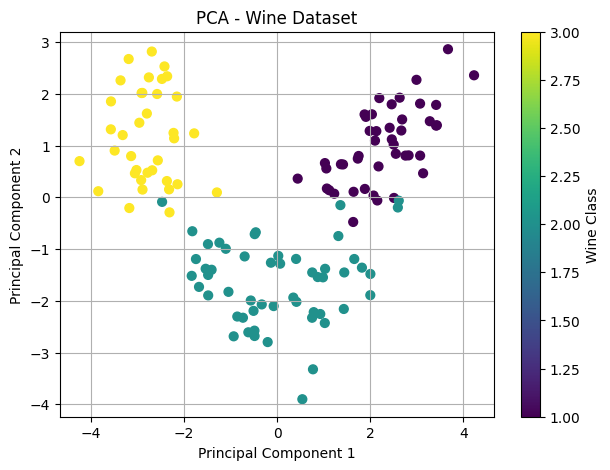


Confusion Matrix:
[[13  2  0]
 [ 0 18  0]
 [ 0  0 12]]

Accuracy: 95.55555555555556 %

Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.87      0.93        15
           2       0.90      1.00      0.95        18
           3       1.00      1.00      1.00        12

    accuracy                           0.96        45
   macro avg       0.97      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



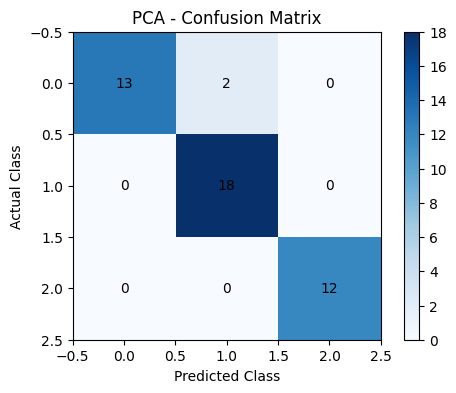

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report
)

# -----------------------------------
# 1. LOAD DATASET
# -----------------------------------

df = pd.read_csv(r"C:\lab\AML-LAB\data\Wine.csv")

print("Dataset:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

# Features and target
X = df.iloc[:, 0:13].values
y = df.iloc[:, 13].values


# -----------------------------------
# 2. SPLIT DATASET
# -----------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)


# -----------------------------------
# 3. STANDARDIZE FEATURES
# -----------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# -----------------------------------
# 4. APPLY PCA
# -----------------------------------

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(sum(pca.explained_variance_ratio_) * 100, "%")


# -----------------------------------
# 5. VISUALIZE PCA COMPONENTS
# -----------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="viridis",
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Dataset")
plt.colorbar(label="Wine Class")
plt.grid()
plt.show()


# -----------------------------------
# 6. TRAIN LOGISTIC REGRESSION
# -----------------------------------

classifier = LogisticRegression(
    solver="lbfgs",
    max_iter=1000
)

classifier.fit(X_train_pca, y_train)


# -----------------------------------
# 7. PREDICT TEST DATA
# -----------------------------------

y_pred = classifier.predict(X_test_pca)


# -----------------------------------
# 8. MODEL EVALUATION
# -----------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# -----------------------------------
# 9. VISUALIZE CONFUSION MATRIX
# -----------------------------------

plt.figure(figsize=(6, 4))

plt.imshow(cm, cmap="Blues")
plt.title("PCA - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.colorbar()

for i in range(len(cm)):
    for j in range(len(cm)):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center")

plt.show()
